### ORIE 5380 Course Project: Designing an In-Store Pilot Program

In the course project, you'll get experience formulating, testing, and analyzing models for decision support. We'll be exploring a scenario where you are an employee for an online retailer that is looking to partner with a chain of stores to offer in-store pickup and returns to reduce logistics costs. As offering the service requires store space and staff time, you want to pilot the program at *p* of the chain's *N* stores to reduce costs. In part 1, you'll design models that minimize the average and worst-case travel time for customers to a participating store. In part 2, you'll incorporate machine learning predictions to capture customer demand.

This project is an example of a class of optimization problems known as facility location problems. In a facility location problem, you want to decide where to locate facilities to best achieve a goal, like minimizing costs or maximizing utility. Other examples of facility location problems include selecting which airports an airline should select as hubs to minimize costs or selecting where to place fire stations to minimize response times.

You can work through this notebook similarly to the in-class introduction to Gurobi in Python. Information about the in-class Gurobi tutorial is available [here](https://canvas.cornell.edu/courses/88614/discussion_topics/1102292), including instructions on how to setup an academic Gurobi license.

In [1]:
# Import the packages needed to run the notebook
import numpy as np
import pandas as pd
import geopandas as gpd
import plotly.graph_objects as go
import seaborn as sns
import matplotlib.pyplot as plt
import math

import gurobipy as gp
from gurobipy import GRB

#### Test Your Gurobi Academic License

The models in this project are too large to run with the free Gurobi license. Follow the instructions [here](https://canvas.cornell.edu/courses/88614/discussion_topics/1102292) to setup a Gurobi Academic License. You must be on campus to activate your license. **Please ensure your license is setup well in advance of the project deadline.**

The cell below lets you test that your academic license is setup.

In [2]:
# Run this cell to test that your academic license works - you do not need to understand the model or submit anything
# from this cell for the project. If your academic license is **not** setup you will get an error: 
# GurobiError: Model too large for size-limited license
N = 100
c = np.random.rand(N,N)   

m0 = gp.Model('license_test')
x = m0.addVars(N,N, vtype=GRB.BINARY, name="x")     

for n in range(N):
    m0.addConstr(sum(x[n,j] for j in range(N)) == 1, name='row {}'.format(n))
    m0.addConstr(sum(x[i,n] for i in range(N)) == 1, name='col {}'.format(n))

m0.setObjective(sum(c[i,j] * x[i,j] for i in range(N) for j in range(N)), GRB.MINIMIZE)
m0.optimize()

Set parameter Username
Set parameter LicenseID to value 2881019
Academic license - for non-commercial use only - expires 2027-11-03
Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (win64 - Windows 11+.0 (26200.2))

CPU model: Intel(R) Core(TM) Ultra 7 255U, instruction set [SSE2|AVX|AVX2]
Thread count: 12 physical cores, 14 logical processors, using up to 14 threads

Optimize a model with 200 rows, 10000 columns and 20000 nonzeros (Min)
Model fingerprint: 0xb11acb30
Model has 10000 linear objective coefficients
Variable types: 0 continuous, 10000 integer (10000 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [5e-06, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 1e+00]

Found heuristic solution: objective 51.3400795
Presolve time: 0.03s
Presolved: 200 rows, 10000 columns, 20000 nonzeros
Variable types: 0 continuous, 10000 integer (10000 binary)

Root relaxation: objective 1.741165e+00, 217 iterations, 0.00 seconds (0.00 work un

### Part 1: Selecting Stores to Minimize Travel Time

In this section, you'll implement your models to minimize average and worst-case travel time and then visualize and interpret the solutions. You'll test the models on data for 36 stores and 3000 customers in the New York City area. Travel times are [OSRM](https://project-osrm.org/) traffic-free driving times between each customer-store pair. 

The code below to load the data assumes that you've downloaded and unzipped the data folder in the same directory as this notebook. You will need to adjust the filepaths if the data is in another location.

In [3]:
# Load data and set the range of p values we want to test
def read_points(path, **kwargs):
    df = pd.read_csv(path, **kwargs, index_col=0)
    return gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df["longitude"], df["latitude"]), crs="EPSG:4326")

stores = read_points("data/stores.csv")
customers = read_points("data/customers.csv")
p_range = range(1,11)

The following block is the code to visualize the stores and customers on a map. You **do not** need to understand how this code works for the project or quiz, you just need to be able to call the `plot_map` using the instructions below.

`plot_map` takes the stores and customers dataframes and colors the points differently based on the arguments you pass to `solution_col`, `time_col`, and `color_by`:
- `plot_map(customer, stores)`: Plots a map of all customers and stores with fixed blue/grey coloring
- `plot_map(customers, stores, solution_col=SOLUTION_COL, color_by='store')`: Plots a map of selected stores, coloring customers by the store they are assigned to. The code assumes `stores[SOLUTION_COL]` has binary data on whether the store was selected and `customers[SOLUTION_COL]` has the store_id of the store assigned to that customer.
- `plot_map(customers, stores, solution_col=SOLUTION_COL, time_col=TIME_COL, color_by='time')`: Plots a map showing selected stores in red and coloring customers by the travel time to their assigned store. The code assumes `stores[SOLUTION_COL]` has binary data on whether the store was selected and `customers[TIME_COL]` has the travel time for each customer.

In [4]:
# Code to visualize stores and customers on a map
UNSELECTED = "#AEAEB2"   # unselected store color
SELECTED = "indianred"     # selected store color when showing continuous values for customers

# Return n colors from the seaborn deep palette, filtering out the grey which is too close 
# to the value for unselected stores
def store_colors(n):
    deep = [c for c in sns.color_palette("deep").as_hex() if c != "#8c8c8c"]
    return deep[:n] if n <= len(deep) else sns.blend_palette(deep, n_colors=n, as_cmap=False).as_hex()

def merc_y(lat):
    return math.log(math.tan(math.pi / 4 + math.radians(lat) / 2))

# Plot stores, using two markers to produce an 'outline'
def add_stores(fig, stores, color, size, name, outline="#8E8E93", showlegend=True, **kwargs):
    for marker, legend in [(dict(size=size + 3, color=outline), False), (dict(size=size, color=color), showlegend)]:
        fig.add_trace(go.Scattermap(
            lat=stores["latitude"], lon=stores["longitude"], mode="markers", marker=marker,
            name=name, legendgroup=name, showlegend=legend, hoverinfo="skip", **kwargs,
        ))

# Main function to plot customers and stores, see the text block above for instructions on how to produce different maps.
# Scale and pad to adjust the size and padding of the map relative to a 700px base cropped to the data's extent
def plot_map(customers, stores, solution_col=None, time_col=None, color_by="store", scale=0.7, pad=0.1):
    # Determine a bounding box to include all points with padding in Web Mercator
    lons = pd.concat([customers["longitude"], stores["longitude"]])
    lats = pd.concat([customers["latitude"], stores["latitude"]])
    x0, x1 = math.radians(lons.min()), math.radians(lons.max())
    y0, y1 = merc_y(lats.min()), merc_y(lats.max())
    x0, x1 = x0 - pad * (x1 - x0), x1 + pad * (x1 - x0)
    y0, y1 = y0 - pad * (y1 - y0), y1 + pad * (y1 - y0)

    # Calculate the size and center of the map
    height = round(700 * scale)
    width = round(height * (x1 - x0) / (y1 - y0))
    zoom = math.log2(height * 2 * math.pi / (512 * (y1 - y0)))  # map tiles are 512 px at zoom 0
    center = dict(lon=math.degrees((x0 + x1) / 2), lat=math.degrees(2 * math.atan(math.exp((y0 + y1) / 2)) - math.pi / 2))

    fig = go.Figure()
    if solution_col is None:
        # Basic map with just store and customer locations
        fig.add_trace(go.Scattermap(
            lat=customers["latitude"], lon=customers["longitude"], mode="markers",
            marker=dict(size=5, color=store_colors(1)[0], opacity=0.6),
            name="Customer", hoverinfo="skip",
        ))
        add_stores(fig, stores, UNSELECTED, 7, "Store")
    elif color_by == "time":
        # Map with selected stores in red and customers colored by travel time
        selected = stores[stores[solution_col] == 1]
        travel_time = customers[time_col]
        fig.add_trace(go.Scattermap(
            lat=customers["latitude"], lon=customers["longitude"], mode="markers",
            marker=dict(size=5, color=travel_time, colorscale="Viridis", cmin=0, opacity=0.8,
                        colorbar=dict(title=dict(text="Travel time (min)", side="right"), len=0.6, thickness=15)),
            name="Customer", hoverinfo="skip",
        ))
        add_stores(fig, selected, SELECTED, 7, "Selected store", outline="white")
    elif color_by == "store":
        # Map with discrete colormap for selected stores and customers colored by assigned store
        selected = stores[stores[solution_col] == 1]
        colors = store_colors(len(selected))

        # Plot unselected stores
        add_stores(fig, stores[stores[solution_col] == 0], UNSELECTED, 7, "Unselected store", legendrank=3)
        
        # Plot customers for each store
        for k, (color, store_id) in enumerate(zip(colors, selected.index)):
            served = customers[customers[solution_col] == store_id]
            fig.add_trace(go.Scattermap(
                lat=served["latitude"], lon=served["longitude"], mode="markers",
                marker=dict(size=5, color=color, opacity=0.6),
                name="Customer", legendgroup="Customer", showlegend=(k == 0), legendrank=1, hoverinfo="skip",
            ))
    
        # Plot selected stores over all customers 
        for k, (color, store_id) in enumerate(zip(colors, selected.index)):
            add_stores(fig, selected.loc[[store_id]], color, 9, "Selected store", outline="white",
                       showlegend=(k == 0), legendrank=2)
    else:
        raise ValueError(f'color_by must be "store" or "time", not {color_by!r}')

    right = 90 if solution_col is not None and color_by == "time" else 0  # room for the colorbar beside the map
    fig.update_layout(
        map=dict(style="carto-positron", center=center, zoom=zoom),
        width=width + right, height=height, margin=dict(l=0, r=right, t=0, b=0),
        legend=dict(x=0.01, y=0.99, bgcolor="rgba(255,255,255,0.8)"),
    )
    return fig

In [5]:
# Use plot_map to visualize all stores and customers
plot_map(customers, stores).show()

In [6]:
# Format data for the optimization
MAX_TIME = 60
results = {}

N = stores.shape[0]
M = customers.shape[0]

# t is a M x N matrix where t[i,j] is the travel time for customer i to travel to store j
t = customers[['d{}'.format(i) for i in range(stores.shape[0])]].to_numpy()

#### Model 1: Minimize Average Customer Travel Time

In [7]:
# In this cell, implement your model to minimize the average customer travel time
# Once you are happy with your model for a single value of p, copy the code to the loop in the following cell 
# to optimize for p = 1, ..., 10 and collect solution values
model_name = 'mean-dist'
p = 3

m1 = gp.Model(model_name)

# TODO: Implement your model
#m1.addVars, m1.addConstrs, m1.setObjective

#VARS
#which store j the customer i goes to for their travel time
x = {}
for i in range(M):
    for j in range(N):
        x[i,j] = m1.addVar(vtype=GRB.BINARY, name=f"x_{i}_{j}")

#if store j is selected, y[j] = 1, else y[j] = 0
y = {}
for j in range(N):
    y[j] = m1.addVar(vtype=GRB.BINARY, name=f"y_{j}")

#CONSTRAINTS
m1.addConstr(gp.quicksum(y[j] for j in range(N)) == p, name="store_limit") #pick p stores
m1.addConstrs((gp.quicksum(x[i,j] for j in range(N)) == 1 for i in range(M)), name="customer_assignment") #only one store per customer
m1.addConstrs((x[i,j] <= y[j] for i in range(M) for j in range(N)), name="store_open") #store selected must offer pickup

#OBJECTIVE
m1.setObjective((1/M) * gp.quicksum(t[i,j] * x[i,j] for i in range(M) for j in range(N)), GRB.MINIMIZE)

# Set time limit
m1.setParam('time_limit', MAX_TIME)

# Optimize
m1.optimize()

Set parameter TimeLimit to value 60
Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (win64 - Windows 11+.0 (26200.2))

CPU model: Intel(R) Core(TM) Ultra 7 255U, instruction set [SSE2|AVX|AVX2]
Thread count: 12 physical cores, 14 logical processors, using up to 14 threads

Non-default parameters:
TimeLimit  60

Optimize a model with 111001 rows, 108036 columns and 324036 nonzeros (Min)
Model fingerprint: 0x0b948c7c
Model has 107999 linear objective coefficients
Variable types: 0 continuous, 108036 integer (108036 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [7e-05, 2e-02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 3e+00]

Found heuristic solution: objective 22.8659333
Presolve time: 0.40s
Presolved: 111001 rows, 108036 columns, 324036 nonzeros
Variable types: 0 continuous, 108036 integer (108036 binary)
Deterministic concurrent LP optimizer: primal and dual simplex
Showing primal log only...


Root simplex log...

Iteration    

In [8]:
# Use this cell to test your model for p = 1, ..., 10 and collect solution values that you'll use for interpretation and visualization
model_name = 'mean-dist'

for p in p_range:
    print('------------------------------')
    print('Starting p = {}'.format(p))
    # TODO: Copy your model code from the previous cell
    m1 = gp.Model(model_name)
    #m1.addVars, m1.addConstrs, m1.setObjective
    #VARS
    x = {}
    for i in range(M):
        for j in range(N):
            x[i,j] = m1.addVar(vtype=GRB.BINARY, name=f"x_{i}_{j}")

    y = {}
    for j in range(N):
        y[j] = m1.addVar(vtype=GRB.BINARY, name=f"y_{j}")
    #CONSTRAINTS
    m1.addConstr(gp.quicksum(y[j] for j in range(N)) == p, name="store_limit")
    m1.addConstrs((gp.quicksum(x[i,j] for j in range(N)) == 1 for i in range(M)), name="customer_assignment")
    m1.addConstrs((x[i,j] <= y[j] for i in range(M) for j in range(N)), name="store_open")
    #OBJECTIVE
    m1.setObjective((1/M) * gp.quicksum(t[i,j] * x[i,j] for i in range(M) for j in range(N)), GRB.MINIMIZE)
    # Set time limit
    m1.setParam('time_limit', MAX_TIME)
    m1.optimize()

    
    # TODO: Add a binary column to the stores dataframe indiciting if a store is selected in this solution
    soln_col = '{}-p{}'.format(model_name, p)
    stores[soln_col] = 0
    selected_stores = [j for j in range(N) if y[j].X > 0.5]
    stores.loc[selected_stores, soln_col] = 1
    

    # TODO: Add a column to the customers dataframe with the store_id of the closest selected store
    subset_stores = t[:, selected_stores]
    customers[soln_col] = stores.index[selected_stores][np.argmin(subset_stores, axis=1)]

    # TODO: Add a column to the customers dataframe for the minimum travel time for each customer
    time_col = '{}-p{}-time'.format(model_name, p)
    customers[time_col] = np.min(subset_stores, axis=1)

    # TODO: Modify the line below to record the values you'll need later for plotting, such as runtime and objective value
    results[model_name, p] = {"runtime_s": m1.Runtime, "gap_percent": m1.MIPGap * 100, "objective": m1.ObjVal, "mean_time": customers[time_col].mean(), "max_time": customers[time_col].max()}


------------------------------
Starting p = 1
Set parameter TimeLimit to value 60
Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (win64 - Windows 11+.0 (26200.2))

CPU model: Intel(R) Core(TM) Ultra 7 255U, instruction set [SSE2|AVX|AVX2]
Thread count: 12 physical cores, 14 logical processors, using up to 14 threads

Non-default parameters:
TimeLimit  60

Optimize a model with 111001 rows, 108036 columns and 324036 nonzeros (Min)
Model fingerprint: 0x1c3d965f
Model has 107999 linear objective coefficients
Variable types: 0 continuous, 108036 integer (108036 binary)
Coefficient statistics:
  Matrix range     [1e+00, 1e+00]
  Objective range  [7e-05, 2e-02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 1e+00]

Found heuristic solution: objective 20.5816333
Presolve removed 92 rows and 92 columns
Presolve time: 3.97s
Presolved: 110909 rows, 107944 columns, 323760 nonzeros
Variable types: 0 continuous, 107944 integer (107944 binary)
Deterministic concurrent LP optimizer: p

#### Model 2: Minimize Worst-Case Customer Travel Time

In [9]:
# In this cell, implement your model to minimize the worst-case customer travel time
# Once you are happy with your model for a single value of p, copy the code to the loop in the next cell 
# to optimize over p = 1, ..., 10 and collect solution values
model_name = 'max-dist'
p = 3

m2 = gp.Model(model_name)

# TODO: Implement your model

#vars
x = {}
for i in range(M):
    for j in range(N):
        x[i,j] = m2.addVar(vtype=GRB.BINARY, name=f"x_{i}_{j}")

y = {}
for j in range(N):
    y[j] = m2.addVar(vtype=GRB.BINARY, name=f"y_{j}")

z = m2.addVar(lb=0, name='z')

#constraints
m2.addConstrs((z >= gp.quicksum(float(t[i, j]) * x[i, j] for j in range(N)) for i in range(M)), name='max_time') #make sure the worst case for all customers is least of all combos
m2.addConstr(gp.quicksum(y[j] for j in range(N)) == p, name="store_limit")
m2.addConstrs((gp.quicksum(x[i,j] for j in range(N)) == 1 for i in range(M)), name="customer_assignment")
m2.addConstrs((x[i,j] <= y[j] for i in range(M) for j in range(N)), name="store_open")

#objective
m2.setObjective(z, GRB.MINIMIZE)

# Set time limit
m2.setParam('time_limit', MAX_TIME)

# Optimize
m2.optimize()

Set parameter TimeLimit to value 60
Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (win64 - Windows 11+.0 (26200.2))

CPU model: Intel(R) Core(TM) Ultra 7 255U, instruction set [SSE2|AVX|AVX2]
Thread count: 12 physical cores, 14 logical processors, using up to 14 threads

Non-default parameters:
TimeLimit  60

Optimize a model with 114001 rows, 108037 columns and 435035 nonzeros (Min)
Model fingerprint: 0x46dbf6aa
Model has 1 linear objective coefficients
Variable types: 1 continuous, 108036 integer (108036 binary)
Coefficient statistics:
  Matrix range     [2e-01, 7e+01]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 3e+00]

Found heuristic solution: objective 61.7000000
Presolve removed 1507 rows and 1437 columns
Presolve time: 1.41s
Presolved: 112494 rows, 106600 columns, 364453 nonzeros
Variable types: 0 continuous, 106600 integer (106599 binary)
Deterministic concurrent LP optimizer: primal and dual simplex
Showing primal log only.

In [10]:
# Use this cell to test your model for p = 1, ..., 10 and collect solution values that you'll use for interpretation and visualization
model_name = 'max-dist'

for p in p_range:
    print('------------------------------')
    print('Starting p = {}'.format(p))
    m2 = gp.Model(model_name)

    # vars
    x = {}
    for i in range(M):
        for j in range(N):
            x[i,j] = m2.addVar(lb=0, ub=1, vtype=GRB.CONTINUOUS, name=f"x_{i}_{j}")   # continuous (still exact)

    y = {}
    for j in range(N):
        y[j] = m2.addVar(vtype=GRB.BINARY, name=f"y_{j}")

    z = m2.addVar(lb=0, name='z')

    # constraints
    m2.addConstr(gp.quicksum(y[j] for j in range(N)) == p, name="store_limit")
    m2.addConstrs((gp.quicksum(x[i,j] for j in range(N)) == 1 for i in range(M)), name="customer_assignment")
    m2.addConstrs((x[i,j] <= y[j] for i in range(M) for j in range(N)), name="store_open")
    m2.addConstrs((z >= gp.quicksum(float(t[i, j]) * x[i, j] for j in range(N)) for i in range(M)), name='max_time')

    # objective
    m2.setObjective(z, GRB.MINIMIZE)

    # Set time limit
    m2.setParam('TimeLimit', MAX_TIME)

    # Optimize
    m2.optimize()

    # If no feasible solution was found in the time limit, record NaNs and move on
    if m2.SolCount == 0:
        results[model_name, p] = {"runtime_s": m2.Runtime, "gap_percent": np.nan, "objective": np.nan,
                                  "mean_time": np.nan, "max_time": np.nan}
        continue

    # Binary column in the stores dataframe indicating if a store is selected
    soln_col = '{}-p{}'.format(model_name, p)
    stores[soln_col] = 0
    selected_stores = [j for j in range(N) if y[j].X > 0.5]
    stores.loc[stores.index[selected_stores], soln_col] = 1

    # Closest selected store (store_id) for each customer
    subset_stores = t[:, selected_stores]
    customers[soln_col] = stores.index[selected_stores][np.argmin(subset_stores, axis=1)]

    # Minimum travel time for each customer
    time_col = '{}-p{}-time'.format(model_name, p)
    customers[time_col] = np.min(subset_stores, axis=1)

    results[model_name, p] = {"runtime_s": m2.Runtime, "gap_percent": m2.MIPGap * 100, "objective": m2.ObjVal, "mean_time": customers[time_col].mean(), "max_time": customers[time_col].max()}

------------------------------
Starting p = 1
Set parameter TimeLimit to value 60
Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (win64 - Windows 11+.0 (26200.2))

CPU model: Intel(R) Core(TM) Ultra 7 255U, instruction set [SSE2|AVX|AVX2]
Thread count: 12 physical cores, 14 logical processors, using up to 14 threads

Non-default parameters:
TimeLimit  60

Optimize a model with 114001 rows, 108037 columns and 435035 nonzeros (Min)
Model fingerprint: 0x537015e9
Model has 1 linear objective coefficients
Variable types: 108001 continuous, 36 integer (36 binary)
Coefficient statistics:
  Matrix range     [2e-01, 7e+01]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 1e+00]

Found heuristic solution: objective 47.1000000
Presolve removed 109138 rows and 108034 columns
Presolve time: 1.00s
Presolved: 4863 rows, 3 columns, 11588 nonzeros
Variable types: 1 continuous, 2 integer (2 binary)
Performing another presolve...
Presolve removed 4863 rows 

#### Visualize and Interpret Solutions

In [11]:
# Combine results into a dataframe
results_df = pd.DataFrame.from_dict(results, orient="index").rename_axis(["model", "p"]).sort_index()
results_df

runtime_s  gap_percent  objective  mean_time  max_time
model     p                                                         
max-dist  1       1.114     0.000000  45.800000  18.968800      45.8
          2      60.392    10.959365  35.900000  17.296267      35.9
          3      60.112     3.649635  27.400000  15.983767      27.4
          4      60.112     1.839477  26.000000  15.137467      26.0
          5      49.743     0.000000  25.400000  11.823267      25.4
          6      39.837     0.000000  25.400000  12.786933      25.4
          7      14.081     0.000000  25.400000  10.455000      25.4
          8       3.667     0.000000  25.400000   9.829800      25.4
          9       7.193     0.000000  25.400000  10.018167      25.4
          10      7.757     0.000000  25.400000   8.780300      25.4
mean-dist 1      17.783     0.000000  18.118133  18.118133      56.0
          2      17.935     0.000000  13.576400  13.576400      42.5
          3      38.350     0.000000  11.646233  11.646233      42.5
          4       9.796     0.000000   9.975867   9.975867      42.5
          5       8.797     0.000000   9.289367   9.289367      31.7
          6      10.575     0.000000   8.638700   8.638700      31.7
          7      13.933     0.000000   8.240300   8.240300      31.7
          8       8.445     0.000000   7.868267   7.868267      29.4
          9       7.706     0.000000   7.544033   7.544033      29.4
          10      5.738     0.000000   7.335367   7.335367      29.4

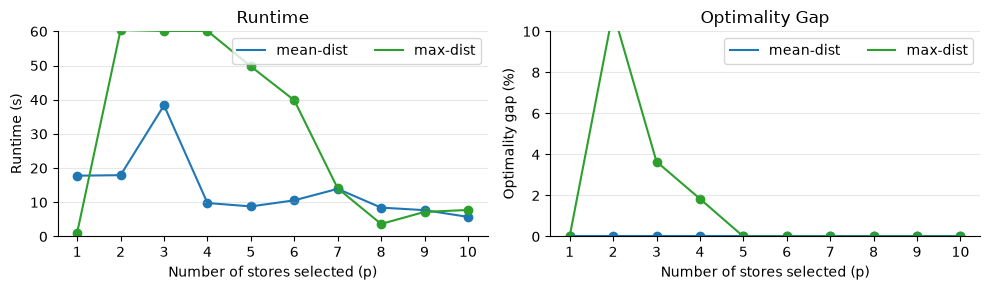

In [12]:
# The code below produces a plot of runtime and optimality gap for each model and value of p
# TODO: Change the constants below to the correct columns in results_df for runtime and optimality gap, 
#       changing the title/labels if your columns use different units
RUNTIME_COL = 'runtime_s'
OPTGAP_COL = 'gap_percent'

RUNTIME_TITLE, RUNTIME_YLABEL, RUNTIME_XLABEL = ('Runtime', 'Runtime (s)', 'Number of stores selected (p)')
OPTGAP_TITLE, OPTGAP_YLABEL, OPTGAP_XLABEL = ('Optimality Gap', 'Optimality gap (%)', 'Number of stores selected (p)')

# Model colormap
model_colors = {"mean-dist": "tab:blue", "max-dist": "tab:green"}

# Axes formatting and labels
def format_plot(title, ylabel, xlabel, legend_bbox=None):
    plt.title(title)
    plt.ylabel(ylabel)
    plt.xlabel(xlabel)
    plt.xticks(p_range)
    if legend_bbox != None:
        plt.legend(ncol=2, bbox_to_anchor=legend_bbox)
    else:
        plt.legend(ncol=2)

    ax = plt.gca()
    ax.set_ylim(bottom=0)
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

    plt.tight_layout()

# Create the figure
fig = plt.figure(figsize=(10,3))

# Runtime subplot
plt.subplot(1,2,1)
for model in model_colors.keys():
    res = results_df.loc[model]
    plt.plot(res.index, res[RUNTIME_COL], color=model_colors[model], label=model)
    plt.scatter(res.index, res[RUNTIME_COL], color=model_colors[model])

format_plot(title=RUNTIME_TITLE, ylabel=RUNTIME_YLABEL, xlabel=RUNTIME_XLABEL)
plt.ylim([0,60])

# Optimality gap subplot
plt.subplot(1,2,2)
for model in model_colors.keys():
    res = results_df.loc[model]
    plt.plot(res.index, res[OPTGAP_COL], color=model_colors[model], label=model)
    plt.scatter(res.index, res[OPTGAP_COL], color=model_colors[model])

format_plot(title=OPTGAP_TITLE, ylabel=OPTGAP_YLABEL, xlabel=OPTGAP_XLABEL)
plt.ylim([0,10])
plt.show()

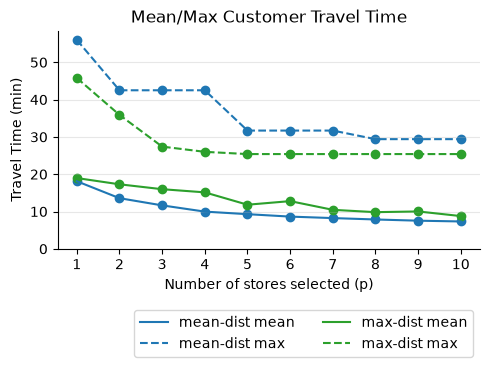

In [13]:
# The code below produces a plot of average and worst-case customer travel distance for each model and value of p
# TODO: Change the constants below to the correct columns in results_df for average and max travel distance 
#       changing the title/labels if your columns use different units
MEAN_DIST_COL = 'mean_time'
MAX_DIST_COL = 'max_time'

DIST_TITLE, DIST_YLABEL, DIST_XLABEL = ('Mean/Max Customer Travel Time', 'Travel Time (min)', 'Number of stores selected (p)')

# Create the figure
fig = plt.figure(figsize=(5,4))
for model in model_colors.keys():
    res = results_df.loc[model]

    # Average customer travel time
    plt.plot(res.index, res[MEAN_DIST_COL], color=model_colors[model], linestyle='-', label='{} mean'.format(model))
    plt.scatter(res.index, res[MEAN_DIST_COL], color=model_colors[model])

    # Worst-case customer travel time
    plt.plot(res.index, res[MAX_DIST_COL], color=model_colors[model], linestyle='--', label='{} max'.format(model))
    plt.scatter(res.index, res[MAX_DIST_COL], color=model_colors[model])

format_plot(title=DIST_TITLE, ylabel=DIST_YLABEL, xlabel=DIST_XLABEL, legend_bbox=(1, -0.25))
plt.show()

In [21]:
# TODO: Set the solution column below to visualize selected stores and the closest customer to each store for a specific solution
# You can uncomment the line below to save a png of the map for your report

for SOLUTION_COL in ['mean-dist-p5', 'max-dist-p5']:
    print(SOLUTION_COL)
    fig = plot_map(customers, stores, solution_col=SOLUTION_COL)
    # fig.write_image('{}.png'.format(SOLUTION_COL), scale=2)   # uncomment to save a png for the report
    fig.show()

mean-dist-p5


max-dist-p5


In [22]:
# TODO: Set the solution column below to visualize selected stores and the closest customer to each store for a specific solution
for SOLUTION_COL in ['mean-dist-p5', 'max-dist-p5']:
    TIME_COL = SOLUTION_COL + '-time'
    print(SOLUTION_COL)
    fig = plot_map(customers, stores, solution_col=SOLUTION_COL, time_col=TIME_COL, color_by="time")
    fig.show()

mean-dist-p5


max-dist-p5


### Part 2: Selecting Stores Based on Customer Usage

In this section, you'll implement and analyze two models incorporating machine learning predictions to select locations incorporating customer demand.

In [14]:
# Load and format predictions for the optimization
predictions = pd.read_csv('data/customer-predictions.csv', index_col=0)
store_predictions = pd.read_csv('data/customer-store-predictions.csv', index_col=0)

P = predictions[['p']].to_numpy().reshape((M))                          # P[i] is the predicted probability that customer i uses the service at any location
Ps = store_predictions[['p{}'.format(i) for i in range(N)]].to_numpy()  # Ps[i,j] is the predicted probability the customer i uses the service at location j

#### Model 3: Minimize Expected Customer Travel Time

In [15]:
# In this cell, implement your model to minimize the expected customer travel time
# Once you are happy with your model for a single value of p, copy the code to the loop in the following cell 
# to optimize for p = 1, ..., 10 and collect solution values
model_name = 'pred-customer'
p = 3

m3 = gp.Model(model_name)

# TODO: Implement your model

# Set time limit
m3.setParam('time_limit', MAX_TIME)

# Optimize
m3.optimize()

Set parameter TimeLimit to value 60
Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (win64 - Windows 11+.0 (26200.2))

CPU model: Intel(R) Core(TM) Ultra 7 255U, instruction set [SSE2|AVX|AVX2]
Thread count: 12 physical cores, 14 logical processors, using up to 14 threads

Non-default parameters:
TimeLimit  60

Optimize a model with 0 rows, 0 columns and 0 nonzeros (Min)
Model fingerprint: 0xf9715da1
Model has 0 linear objective coefficients
Coefficient statistics:
  Matrix range     [0e+00, 0e+00]
  Objective range  [0e+00, 0e+00]
  Bounds range     [0e+00, 0e+00]
  RHS range        [0e+00, 0e+00]

Presolve time: 0.00s
Presolve: All rows and columns removed
Iteration    Objective       Primal Inf.    Dual Inf.      Time
       0    0.0000000e+00   0.000000e+00   0.000000e+00      0s

Solved in 0 iterations and 0.00 seconds (0.00 work units)
Optimal objective  0.000000000e+00


In [16]:
# Use this cell to test your model for p = 1, ..., 10 and collect solution values that you'll use for interpretation and visualization
model_name = 'min-exp-dist'

for p in p_range:
    print('------------------------------')
    print('Starting p = {}'.format(p))
    # TODO: Copy your model code

    # TODO: Add a binary column to the stores dataframe indiciting if a store is selected in this solution
    soln_col = '{}-p{}'.format(model_name, p)
    stores[soln_col] = 0

    # TODO: Add a column to the customers dataframe for the closest selected store to each customer
    soln_col = '{}-p{}'.format(model_name, p)
    customers[soln_col] = 0

    # TODO: Add a column to the customers dataframe for the minimum travel time for each customer
    time_col = '{}-p{}-time'.format(model_name, p)
    customers[time_col] = 0

    # TODO: Modify the line below to record the values you'll need later for plotting, such as runtime or objective value
    results[model_name, p] = {"runtime_s": 0, "gap_percent": 0, "objective": 0}

------------------------------
Starting p = 1
------------------------------
Starting p = 2
------------------------------
Starting p = 3
------------------------------
Starting p = 4
------------------------------
Starting p = 5
------------------------------
Starting p = 6
------------------------------
Starting p = 7
------------------------------
Starting p = 8
------------------------------
Starting p = 9
------------------------------
Starting p = 10


#### Model 4: Maximize Expected Usage

In [17]:
# In this cell, implement your model to maximize the expected number of customer using the in-store service
# Once you are happy with your model for a single value of p, copy the code to the loop in the following cell 
# to optimize for p = 1, ..., 10 and collect solution values
model_name = 'pred-customer-store'
p = 3

m4 = gp.Model(model_name)

# TODO: Implement your model

# Set time limit
m4.setParam('time_limit', MAX_TIME)

# Optimize
m4.optimize()

Set parameter TimeLimit to value 60
Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (win64 - Windows 11+.0 (26200.2))

CPU model: Intel(R) Core(TM) Ultra 7 255U, instruction set [SSE2|AVX|AVX2]
Thread count: 12 physical cores, 14 logical processors, using up to 14 threads

Non-default parameters:
TimeLimit  60

Optimize a model with 0 rows, 0 columns and 0 nonzeros (Min)
Model fingerprint: 0xf9715da1
Model has 0 linear objective coefficients
Coefficient statistics:
  Matrix range     [0e+00, 0e+00]
  Objective range  [0e+00, 0e+00]
  Bounds range     [0e+00, 0e+00]
  RHS range        [0e+00, 0e+00]

Presolve time: 0.00s
Presolve: All rows and columns removed
Iteration    Objective       Primal Inf.    Dual Inf.      Time
       0    0.0000000e+00   0.000000e+00   0.000000e+00      0s

Solved in 0 iterations and 0.01 seconds (0.00 work units)
Optimal objective  0.000000000e+00


In [18]:
# Use this cell to test your model for p = 1, ..., 10 and collect solution values that you'll use for interpretation and visualization
model_name = 'max-exp-usage'

for p in p_range:
    print('------------------------------')
    print('Starting p = {}'.format(p))
    # TODO: Copy your model code

    # TODO: Add a binary column to the stores dataframe indiciting if a store is selected in this solution
    soln_col = '{}-p{}'.format(model_name, p)
    stores[soln_col] = 0

    # TODO: Add a column to the customers dataframefor the store the customer was assigned to
    soln_col = '{}-p{}'.format(model_name, p)
    customers[soln_col] = 0

    # TODO: Add a column to the customers dataframe for the travel time to the store the customer was assigned to
    #       Note: In this model the customer may not go to the nearest store
    time_col = '{}-p{}-time'.format(model_name, p)
    customers[time_col] = 0

    # TODO: Modify the line below to record the values you'll need later for plotting, such as runtime or objective value
    results[model_name, p] = {"runtime_s": 0, "gap_percent": 0, "objective": 0}

------------------------------
Starting p = 1
------------------------------
Starting p = 2
------------------------------
Starting p = 3
------------------------------
Starting p = 4
------------------------------
Starting p = 5
------------------------------
Starting p = 6
------------------------------
Starting p = 7
------------------------------
Starting p = 8
------------------------------
Starting p = 9
------------------------------
Starting p = 10


#### Visualize and Interpret Solutions

In [19]:
# Combine results into a dataframe
results_df = pd.DataFrame.from_dict(results, orient="index").rename_axis(["model", "p"]).sort_index()
results_df.loc[["min-exp-dist", "max-exp-usage"]]

runtime_s  gap_percent  objective  mean_time  max_time
model         p                                                         
min-exp-dist  1         0.0          0.0        0.0        NaN       NaN
              2         0.0          0.0        0.0        NaN       NaN
              3         0.0          0.0        0.0        NaN       NaN
              4         0.0          0.0        0.0        NaN       NaN
              5         0.0          0.0        0.0        NaN       NaN
              6         0.0          0.0        0.0        NaN       NaN
              7         0.0          0.0        0.0        NaN       NaN
              8         0.0          0.0        0.0        NaN       NaN
              9         0.0          0.0        0.0        NaN       NaN
              10        0.0          0.0        0.0        NaN       NaN
max-exp-usage 1         0.0          0.0        0.0        NaN       NaN
              2         0.0          0.0        0.0        NaN       NaN
              3         0.0          0.0        0.0        NaN       NaN
              4         0.0          0.0        0.0        NaN       NaN
              5         0.0          0.0        0.0        NaN       NaN
              6         0.0          0.0        0.0        NaN       NaN
              7         0.0          0.0        0.0        NaN       NaN
              8         0.0          0.0        0.0        NaN       NaN
              9         0.0          0.0        0.0        NaN       NaN
              10        0.0          0.0        0.0        NaN       NaN

KeyError: ''

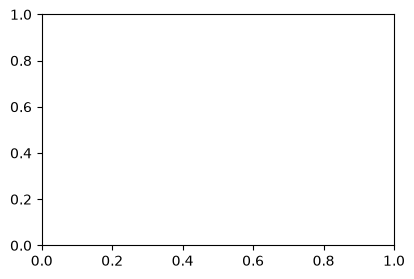

In [20]:
# The code below produces a plot of runtime and optimality gap for each model and value of p
# TODO: Change the constants below to the correct columns in results_df for runtime and optimality gap, 
#       changing the title/labels if your columns use different units
RUNTIME_COL = ''
OPTGAP_COL = ''

RUNTIME_TITLE, RUNTIME_YLABEL, RUNTIME_XLABEL = ('Runtime', 'Runtime (s)', 'Number of stores selected (p)')
OPTGAP_TITLE, OPTGAP_YLABEL, OPTGAP_XLABEL = ('Optimality Gap', 'Optimality gap (%)', 'Number of stores selected (p)')

# Model colormap
model_colors = {"min-exp-dist": "tab:purple", "max-exp-usage": "tab:red"}

# Create the figure
fig = plt.figure(figsize=(10,3))

# Runtime subplot
plt.subplot(1,2,1)
for model in model_colors.keys():
    res = results_df.loc[model]
    plt.plot(res.index, res[RUNTIME_COL], color=model_colors[model], label=model)
    plt.scatter(res.index, res[RUNTIME_COL], color=model_colors[model])

format_plot(title=RUNTIME_TITLE, ylabel=RUNTIME_YLABEL, xlabel=RUNTIME_XLABEL, legend_bbox=(0.875, -0.25))
plt.ylim([0,60])

# Optimality gap subplot
plt.subplot(1,2,2)
for model in model_colors.keys():
    res = results_df.loc[model]
    plt.plot(res.index, res[OPTGAP_COL], color=model_colors[model], label=model)
    plt.scatter(res.index, res[OPTGAP_COL], color=model_colors[model])

format_plot(title=OPTGAP_TITLE, ylabel=OPTGAP_YLABEL, xlabel=OPTGAP_XLABEL, legend_bbox=(0.875, -0.25))
plt.ylim([0,10])
plt.show()

In [ ]:
# The code below produces a plot of the expected number of customers average and worst-case customer travel distance
# for the two models incorporating predictions for each value of p
# TODO: Change the constants below to the correct columns in results_df for the expected number of customers and expected
#       average and worst-case distance columns changing the title/label columns if you used different units
EXP_CUSTOMER_COL = ''
MEAN_DIST_COL = ''
MAX_DIST_COL = ''

CUSTOMERS_TITLE, CUSTOMERS_YLABEL, CUSTOMERS_XLABEL = ('Expected Number of Customers', '# Customers', 'Number of stores selected (p)')
EXP_DIST_TITLE, EXP_DIST_YLABEL, EXP_DIST_XLABEL = ('Mean/Max Expected Customer Travel Time', 'Travel Time (min)', 'Number of stores selected (p)')

# Create the figure
fig = plt.figure(figsize=(10,4))

# Expected customers
plt.subplot(1,2,1)
for model in model_colors.keys():
    res = results_df.loc[model]

    plt.plot(res.index, res[EXP_CUSTOMER_COL], color=model_colors[model], label=model)
    plt.scatter(res.index, res[EXP_CUSTOMER_COL], color=model_colors[model])

format_plot(title=CUSTOMERS_TITLE, ylabel=CUSTOMERS_YLABEL, xlabel=CUSTOMERS_XLABEL, legend_bbox=(0.9, -0.25))

# Expected travel distance
plt.subplot(1,2,2)
for model in model_colors.keys():
    res = results_df.loc[model]

    # Average customer travel time
    plt.plot(res.index, res[MEAN_DIST_COL], color=model_colors[model], label=model)
    plt.scatter(res.index, res[MEAN_DIST_COL], color=model_colors[model])

    # Worst-case customer travel time
    plt.plot(res.index, res[MAX_DIST_COL], color=model_colors[model], linestyle='--', label=model)
    plt.scatter(res.index, res[MAX_DIST_COL], color=model_colors[model])

format_plot(title=EXP_DIST_TITLE, ylabel=EXP_DIST_YLABEL, xlabel=EXP_DIST_XLABEL, legend_bbox=(0.9, -0.25))
plt.ylim([0,50])
plt.show()

In [ ]:
# TODO: Set the solution column below to visualize selected stores and the closest customer to each store for a specific solution
SOLUTION_COL = ''

fig = plot_map(customers, stores, solution_col=SOLUTION_COL)
# fig.write_image('fig.png', scale=2)
fig.show()

In [ ]:
# TODO: Set the solution column below to visualize selected stores and the closest customer to each store for a specific solution
SOLUTION_COL = ''
TIME_COL = ''

fig = plot_map(customers, stores, solution_col=SOLUTION_COL, time_col=TIME_COL, color_by="time")
fig.show()